# Regression Error Metrics

## Learning Objectives

- Understand residuals.
- Calculate MSE, MAE, and RMSE.
- Compare the behavior of different error metrics.
- Understand the effect of outliers.
- Evaluate a regression model using multiple metrics.

We will use a synthetic dataset representing years of experience and salary.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.DataFrame({
    "experience": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "salary": [25, 30, 35, 45, 48, 55, 60, 65, 72, 78]
})

data

,experience,salary
0,1,25
1,2,30
2,3,35
3,4,45
4,5,48
5,6,55
6,7,60
7,8,65
8,9,72
9,10,78


## 1. Build a Linear Regression Model

We will fit a simple linear regression model using NumPy's least-squares implementation.

The hypothesis is:

$$
\hat{y} = \theta_0 + \theta_1x
$$

Where:
- $x$ = years of experience.
- $\hat{y}$ = predicted salary.

In [3]:
X = data[["experience"]].to_numpy(dtype=float)
y = data["salary"].to_numpy(dtype=float)

X_design = np.column_stack([np.ones(len(X)), X])

theta = np.linalg.lstsq(X_design, y, rcond=None)[0]

y_pred = X_design @ theta

print(f"Intercept: {theta[0]:.4f}")
print(f"Slope: {theta[1]:.4f}")

Intercept: 18.8667
Slope: 5.8970


## 2. Calculate Residuals

A residual is the difference between the observed target and predicted target.

$$
e_i = y_i-\hat{y}_i
$$

Residuals help us understand how far individual predictions are from actual observations.

In [4]:
residuals = y - y_pred

results = pd.DataFrame({
    "Experience": X.flatten(),
    "Actual Salary": y,
    "Predicted Salary": y_pred,
    "Residual": residuals
})

results.round(2)

,Experience,Actual Salary,Predicted Salary,Residual
0,1.0,25.0,24.76,0.24
1,2.0,30.0,30.66,-0.66
2,3.0,35.0,36.56,-1.56
3,4.0,45.0,42.45,2.55
4,5.0,48.0,48.35,-0.35
5,6.0,55.0,54.25,0.75
6,7.0,60.0,60.15,-0.15
7,8.0,65.0,66.04,-1.04
8,9.0,72.0,71.94,0.06
9,10.0,78.0,77.84,0.16


## 3. Mean Squared Error (MSE)

MSE calculates the average squared difference between actual and predicted values.

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

Large errors receive a disproportionately larger penalty.

In [5]:
def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


mse = mean_squared_error(y, y_pred)

print(f"MSE: {mse:.4f}")

MSE: 1.1224


## 4. Mean Absolute Error (MAE)

MAE calculates the average absolute difference between actual and predicted values.

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

Unlike MSE, it does not square the residuals.

In [6]:
def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))


mae = mean_absolute_error(y, y_pred)

print(f"MAE: {mae:.4f}")

MAE: 0.7515


## 5. Root Mean Squared Error (RMSE)

RMSE is the square root of MSE.

$$
RMSE = \sqrt{MSE}
$$

It expresses the error metric in the same unit as the target variable.

In [7]:
def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


rmse = root_mean_squared_error(y, y_pred)

print(f"RMSE: {rmse:.4f}")

RMSE: 1.0594


In [8]:
metric_comparison = pd.DataFrame({
    "Metric": ["MSE", "MAE", "RMSE"],
    "Value": [mse, mae, rmse]
})

metric_comparison

,Metric,Value
0,MSE,1.122424
1,MAE,0.751515
2,RMSE,1.059445


## 6. Actual vs Predicted Values

Let's visualize the regression line and compare the actual salary values with model predictions.

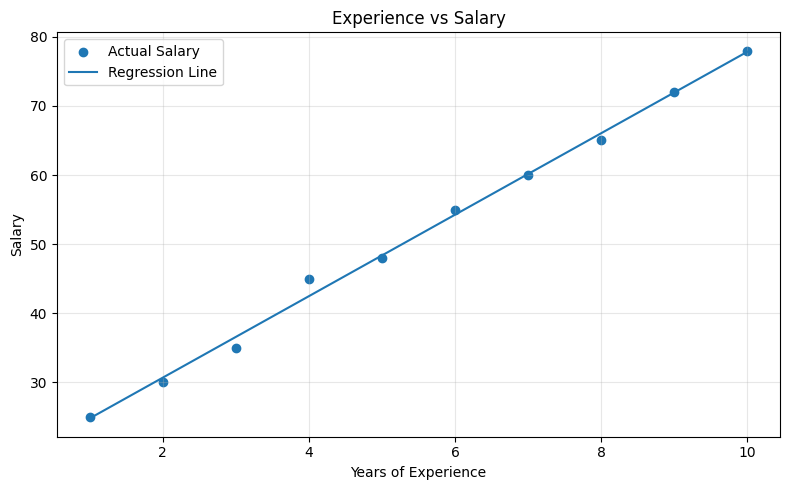

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(X, y, label="Actual Salary")
plt.plot(X, y_pred, label="Regression Line")

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Experience vs Salary")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

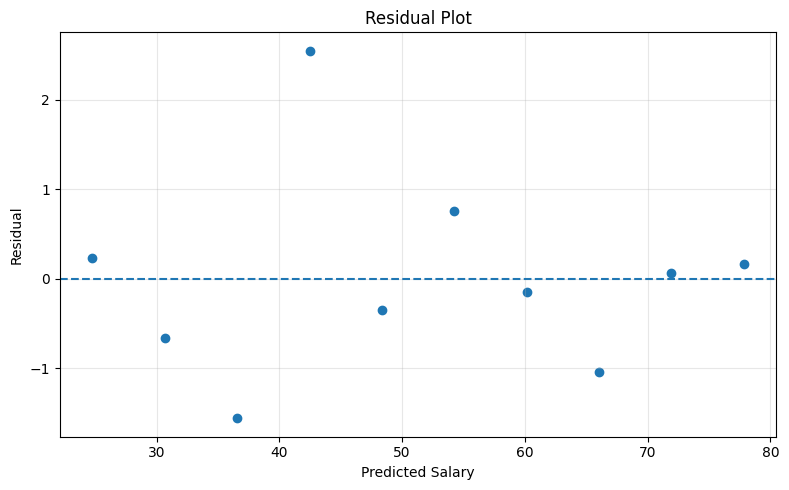

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Salary")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Understanding Outlier Sensitivity

MSE and RMSE penalize large residuals more heavily because they square the errors.

MAE uses absolute residuals, so the penalty increases linearly.

Let's introduce one unusually large prediction error and observe how the metrics change.

In [11]:
y_pred_with_outlier = y_pred.copy()

# Introduce a large prediction error for one observation.
y_pred_with_outlier[-1] += 100

normal_metrics = {
    "MSE": mean_squared_error(y, y_pred),
    "MAE": mean_absolute_error(y, y_pred),
    "RMSE": root_mean_squared_error(y, y_pred)
}

outlier_metrics = {
    "MSE": mean_squared_error(y, y_pred_with_outlier),
    "MAE": mean_absolute_error(y, y_pred_with_outlier),
    "RMSE": root_mean_squared_error(y, y_pred_with_outlier)
}

outlier_comparison = pd.DataFrame({
    "Original": normal_metrics,
    "With Large Error": outlier_metrics
})

outlier_comparison.round(3)

,Original,With Large Error
MSE,1.122,997.850
MAE,0.752,10.719
RMSE,1.059,31.589


## 8. Interpretation

Observe how each metric changes after introducing a large prediction error.

- MSE increases substantially because the residual is squared.
- RMSE also increases substantially, but remains in the target's original unit.
- MAE increases linearly with the absolute error.

This demonstrates why MSE and RMSE are more sensitive to large errors than MAE.

## 9. Evaluate the Model Using Multiple Metrics

Error metrics and explained-variation metrics provide complementary information.

We will calculate:

- MSE
- MAE
- RMSE
- R²
- Adjusted R²

This gives us a broader view of model performance.

In [12]:
def calculate_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    if np.isclose(ss_tot, 0):
        raise ValueError("R² is undefined when target variation is zero.")

    return 1 - (ss_res / ss_tot)


def calculate_adjusted_r2(r2, n, p):
    if n - p - 1 <= 0:
        raise ValueError("Residual degrees of freedom must be positive.")

    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


n = len(y)
p = X.shape[1]

r2 = calculate_r2(y, y_pred)
adjusted_r2 = calculate_adjusted_r2(r2, n, p)

evaluation = pd.DataFrame({
    "Metric": ["MSE", "MAE", "RMSE", "R²", "Adjusted R²"],
    "Value": [
        mse,
        mae,
        rmse,
        r2,
        adjusted_r2
    ]
})

evaluation.round(4)

,Metric,Value
0,MSE,1.1224
1,MAE,0.7515
2,RMSE,1.0594
3,R²,0.9961
4,Adjusted R²,0.9956


## 10. Self-Check

1. What is a residual?
2. Why does MSE square the residuals?
3. Why is MSE sensitive to outliers?
4. Why is MAE more robust to large errors?
5. Why is RMSE preferred over MSE in some reporting situations?
6. Which metric is expressed in squared units?
7. Which metric is not differentiable at zero?
8. Why should we evaluate a model using multiple metrics?

### Answers

1. Observed value minus predicted value.
2. Squaring produces a differentiable quadratic objective and penalizes large errors more heavily.
3. Large residuals become disproportionately large when squared.
4. MAE uses absolute errors instead of squared errors.
5. RMSE is expressed in the same unit as the target variable.
6. MSE.
7. MAE.
8. Different metrics reveal different aspects of model performance and prediction error.